# Лабораторная работа №1. Linear Regression и Logistic Regression

**Дисциплина:** «Системы искусственного интеллекта»

**Часть A.** Linear Regression, датасет [Bike Sharing Dataset](https://www.kaggle.com/datasets/marklvl/bike-sharing-dataset), целевая переменная `cnt`.

**Часть B.** Logistic Regression, датасет [Spaceship Titanic](https://www.kaggle.com/competitions/spaceship-titanic), целевая переменная `Transported`.

Обе модели реализованы вручную на PyTorch: свой класс, свой цикл обучения, градиент через `autograd`, обновление весов вручную. Готовые модели, `torch.nn`, `torch.optim`, split, scaler и imputer из sklearn не используются, из `sklearn.metrics` берутся только метрики для проверки.

### Содержание
1. Введение и настройка окружения
2. Часть A. Linear Regression: обзор данных
3. Часть A. Preprocessing и train/test split
4. Часть A. Класс LinearRegression
5. Часть A. Обучение и оценка
6. Часть B. Logistic Regression: обзор данных
7. Часть B. Preprocessing и train/test split
8. Часть B. Класс LogisticRegression
9. Часть B. Обучение и оценка
10. Выводы

In [4]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss, confusion_matrix

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.titleweight'] = 'bold'

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
DTYPE = torch.float32

## Загрузка данных

In [205]:
df = pd.read_csv('data_part_A/day.csv')
print(f'Строк: {df.shape[0]}, столбцов: {df.shape[1]}')
df.head()

Строк: 731, столбцов: 16


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [89]:
print(f'\nПропусков всего: {df.isna().sum().sum()}')
print(f'Дубликатов строк: {df.duplicated().sum()}')


Пропусков всего: 0
Дубликатов строк: 0


In [90]:
print(df['cnt'].describe().round(1))
print(f'\ncnt == casual + registered: {(df["cnt"] == df["casual"] + df["registered"]).all()}')

count     731.0
mean     4504.3
std      1937.2
min        22.0
25%      3152.0
50%      4548.0
75%      5956.0
max      8714.0
Name: cnt, dtype: float64

cnt == casual + registered: True


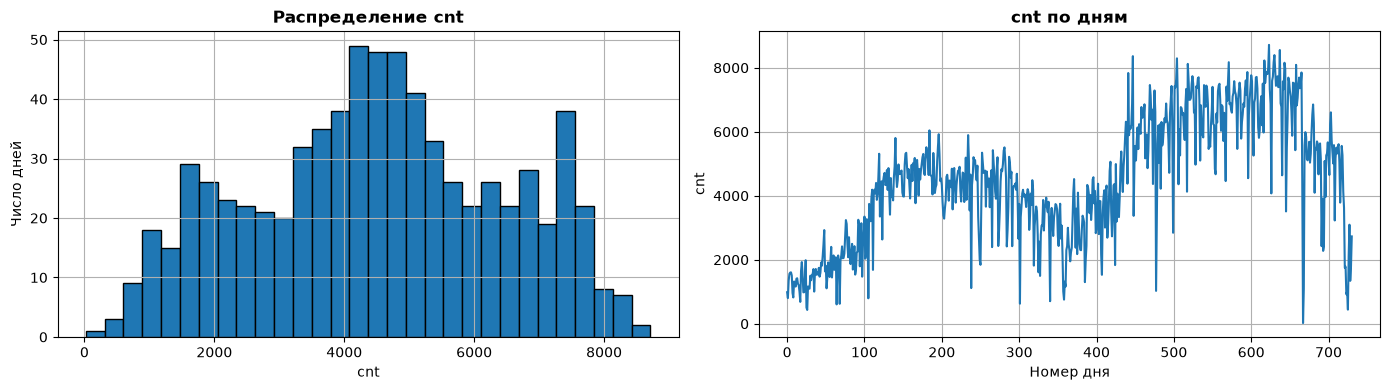

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df['cnt'], bins=30, edgecolor='black')
axes[0].set_title('Распределение cnt')
axes[0].set_xlabel('cnt')
axes[0].set_ylabel('Число дней')

axes[1].plot(df['cnt'].values)
axes[1].set_title('cnt по дням')
axes[1].set_xlabel('Номер дня')
axes[1].set_ylabel('cnt')

plt.tight_layout()
plt.show()

# 2. Сформировать X и y.

In [92]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [94]:
DROP_COLS = ['instant', 'dteday', 'casual', 'registered', 'cnt']
CAT_COLS = ['season', 'mnth', 'weekday', 'weathersit']
BIN_COLS = ['yr', 'holiday', 'workingday']
REAL_COLS = ['temp', 'atemp', 'hum', 'windspeed']
# разделение на X и y
y = df['cnt']
X = df.drop(columns=DROP_COLS)
X.shape, y.shape

((731, 11), (731,))

## 3 Обработка пропусков и категориальных признаков
Целевая переменная `cnt`. Из признаков я исключаю следующее:
- `casual` и `registered` из-за линейной комбинации c целевой переменной `cnt=casual+registered`. 
- `instant` - повторяет нумерацию строк.
-  `dteday` -  комбинация года `yr`, месяца `mnth`.

Категориальные признаки: `season`, `mnth`, `weekday`, `weathersit`. Они хранятся числовым типом данных, когда на саомо деле порядка между категориями нет. Воспользуемся `one-hot кодированием` категориальных признаков.

Признаки `yr`, `holiday` и `workingday` являются бинарными, они уже совпадают с `one-hot кодированием`, поэтому дополнительной предобработки производить не нужно.

In [93]:
print(f'\nПропусков всего: {df.isna().sum().sum()}')
print(f'Дубликатов строк: {df.duplicated().sum()}')


Пропусков всего: 0
Дубликатов строк: 0


In [95]:
# One-hot кодирование категориальных признаков
X = pd.get_dummies(X, columns=CAT_COLS, drop_first=True, dtype=float)

In [96]:
X.columns.tolist()

['yr',
 'holiday',
 'workingday',
 'temp',
 'atemp',
 'hum',
 'windspeed',
 'season_2',
 'season_3',
 'season_4',
 'mnth_2',
 'mnth_3',
 'mnth_4',
 'mnth_5',
 'mnth_6',
 'mnth_7',
 'mnth_8',
 'mnth_9',
 'mnth_10',
 'mnth_11',
 'mnth_12',
 'weekday_1',
 'weekday_2',
 'weekday_3',
 'weekday_4',
 'weekday_5',
 'weekday_6',
 'weathersit_2',
 'weathersit_3']

In [97]:
X.head()

,yr,holiday,workingday,temp,atemp,hum,windspeed,season_2,season_3,season_4,mnth_2,mnth_3,mnth_4,mnth_5,mnth_6,mnth_7,mnth_8,mnth_9,mnth_10,mnth_11,mnth_12,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,weathersit_2,weathersit_3
0,0,0,0,0.344167,0.363625,0.805833,0.160446,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,0,0,0,0.363478,0.353739,0.696087,0.248539,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0,0,1,0.196364,0.189405,0.437273,0.248309,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0,1,0.200000,0.212122,0.590435,0.160296,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0,1,0.226957,0.229270,0.436957,0.186900,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## 4. Самописный train/test split

In [98]:
# переводим array numpy в tensor torch 
X_t = torch.tensor(X.values, dtype=DTYPE)
y_t = torch.tensor(y.values, dtype=DTYPE)
feature_names = X.columns.tolist()

In [99]:
def train_test_split(X, y, test_size=0.3, seed=RANDOM_STATE):
    generator = torch.Generator().manual_seed(seed) # генератор cлучайных для выбора случайным образом индексов объектов датасета
    idx = torch.randperm(X.shape[0], generator=generator) # случайная перестановка индексов объектов [0, n-1]
    n_test = int(X.shape[0] * test_size)
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = train_test_split(X_t, y_t)

## 5. Препроцессинг данных
Стандартизируем вещественные и целочисленные признаки `temp`, `atemp`, `hum`, `windspeed`, используя вычитания среднего и делится на стандартное отклонение. Среднее и стандартное отклонение считаются только по `train`, а используются на `train` и `test` для того, чтобы информация об тестовых данных не попала в обучение. В простонародии это называется `data leakage`.

Бинарные столбцы и one-hot столбцы и так уже лежать в диапозоне [0, 1].

In [100]:
REAL_COLS = ['temp', 'atemp', 'hum', 'windspeed']
num_idx = [feature_names.index(c) for c in REAL_COLS] # номера столбцов REAL_COLS, в тезноре нет имён у столбцов

train_mean = X_train[:, num_idx].mean(dim=0)
train_std = X_train[:, num_idx].std(dim=0)

X_train_s = X_train.clone()
X_test_s = X_test.clone()
X_train_s[:, num_idx] = (X_train[:, num_idx] - train_mean) / train_std
X_test_s[:, num_idx] = (X_test[:, num_idx] - train_mean) / train_std

In [103]:
print(f'Среднее train после стандартизации: {X_train_s[:, num_idx].mean(dim=0)}')
print(f'Стандартное отклонение train после стандартизации: {X_train_s[:, num_idx].std(dim=0)}')

Среднее train после стандартизации: tensor([ 8.2888e-08, -1.3784e-07,  4.3213e-07, -3.3528e-08])
Стандартное отклонение train после стандартизации: tensor([1.0000, 1.0000, 1.0000, 1.0000])


## 6. Реализация собственного класса Linear Regression.

In [110]:
X_test_s.dtype

torch.float32

In [126]:
class LinearRegression:
    def __init__(self, lr=0.01, n_epochs=1000):
        self.lr = lr
        self.n_epochs = n_epochs
        self.w = None
        self.b = None
        self.loss_history = []

    def fit(self, X, y, X_val=None, y_val=None):
        self.w = torch.zeros(X.shape[1], dtype=torch.float32, requires_grad=True) # requires_grad включает подсчёт автоградиента
        self.b = torch.zeros(1, dtype=torch.float32, requires_grad=True)
        self.loss_history = []
        self.val_loss_history = [] # для вывода 2-го графика

        for _ in range(self.n_epochs):
            y_pred = X @ self.w + self.b
            loss = ((y_pred - y) ** 2).mean()
            loss.backward() # считает градиенты в тензоре через PyTorch Autograd 
            # через метод обратного распространения ошибки (backpropagation)

            with torch.no_grad(): # само обновление весов не должно попадать в граф вычислений, иначе autograd начнёт дифференцировать шаг градиентного спуска.
                self.w -= self.lr * self.w.grad # обновление весов 
                self.b -= self.lr * self.b.grad # обновление свободного коэффициента

            # backward() накапливает градиенты при каждом запуске, то есть аккумулирует градиенты, если их не сбрасывать
            self.w.grad.zero_()
            self.b.grad.zero_()
            self.loss_history.append(loss.item()) # достаём число из тензора

            if X_val is not None:
                with torch.no_grad():
                    self.val_loss_history.append(((X_val @ self.w + self.b - y_val) ** 2).mean().item())

        return self # для того, чтобы можно было писать chain LinearRegression().fit(X, y)

    def predict(self, X):
        with torch.no_grad():
            return X @ self.w + self.b


In [127]:
model = LinearRegression(lr=0.1, n_epochs=2000)
model.fit(X_train_s, y_train, X_test_s, y_test)

In [114]:
print(f'Loss на первой эпохе: {model.loss_history[0]:.1f}')
print(f'Loss на последней эпохе: {model.loss_history[-1]:.1f}')

Loss на первой эпохе: 23616230.0
Loss на последней эпохе: 614068.1


## 7. График loss по эпохам

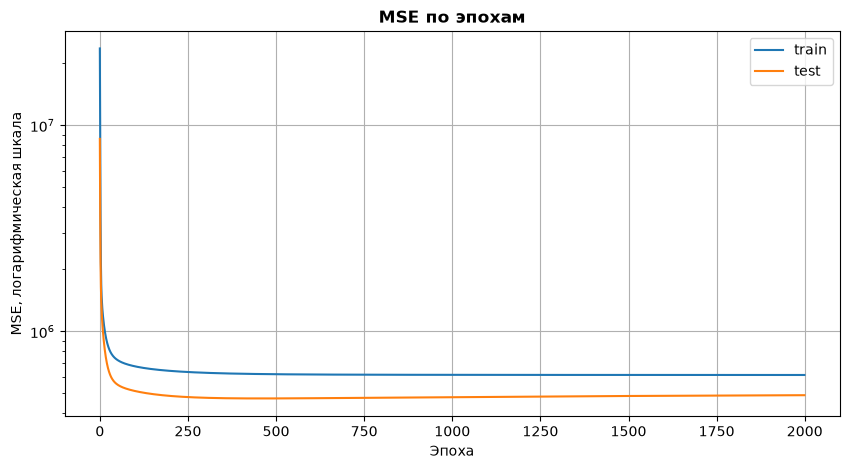

In [128]:
plt.plot(model.loss_history, label='train')
plt.plot(model.val_loss_history, label='test')
plt.yscale('log')
plt.title('MSE по эпохам')
plt.xlabel('Эпоха')
plt.ylabel('MSE, логарифмическая шкала')
plt.legend()
plt.show()

## 8. Метрики и сравнение с baseline

Оценка модели по метрикам `MAE`, `RMSE`, `R²`.

Baseline предсказывает для каждого дня среднее `cnt` по train. Среднее берётся из того, что функция ошибки MSE и для baseline оптимально брать модель, которая выдаёт среднее по все тренировочной выборке.

In [122]:
def evaluate(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
        'R2': r2_score(y_true, y_pred),
    }

y_pred_baseline_train = torch.full_like(y_train, y_train.mean().item())
y_pred_train = model.predict(X_train_s)
y_pred_test = model.predict(X_test_s)
y_pred_baseline_test = torch.full_like(y_test, y_train.mean().item())

results = pd.DataFrame({
    'LinearRegression, train': evaluate(y_train, y_pred_train),
    'Baseline, train': evaluate(y_train, y_pred_baseline_train),
    'LinearRegression, test': evaluate(y_test, y_pred_test),
    'Baseline, test': evaluate(y_test, y_pred_baseline_test),
}).T
results

,MAE,RMSE,R2
"LinearRegression, train",574.139526,783.624751,0.843527
"Baseline, train",1610.114502,1981.016280,0.000000
"LinearRegression, test",510.810730,699.893318,0.851540
"Baseline, test",1522.325928,1830.103139,-0.015069


# 9. Результаты и вывод части A

Loss на train упал с `23616230` до `614068`. Основное снижение приходится на первые сотни эпох, дальше кривая выходит на плато.

| | MAE | RMSE | R² |
|---|---|---|---|
| LinearRegression, train | `574.1` | `783.6` | `0.8435` |
| Baseline, train | `1610.1` | `1981.0` | `0.0000` |
| LinearRegression, test | `510.8` | `699.9` | `0.8515` |
| Baseline, test | `1522.3` | `1830.1` | `-0.0151` |

Модель снижает MAE на test в `3.0` раза, RMSE в `2.6` раза

# Часть B. Logistic Regression

Датасет **Spaceship Titanic** с Kaggle. Задача относится к бинарной классификации:  предсказать, был ли пассажир перенесён в другое измерение или нет. Целевая переменная: `Transported`.

| Признак | Описание |
|---|---|
| `PassengerId` | Уникальный идентификатор пассажира вида `gggg_pp`, где `gggg` - номер группы, с которой путешествует пассажир, а `pp` - его номер внутри группы. Люди в одной группе часто, но не всегда члены одной семьи |
| `HomePlanet` | Планета, с которой пассажир вылетел, как правило планета постоянного проживания |
| `CryoSleep` | Решил ли пассажир на время рейса погрузиться в анабиоз. Пассажиры в криосне остаются в своих каютах |
| `Cabin` | Номер каюты вида `deck/num/side`, где `side` равно `P` (Port, левый борт) или `S` (Starboard, правый борт) |
| `Destination` | Планета, на которой пассажир сойдёт |
| `Age` | Возраст пассажира |
| `VIP` | Оплатил ли пассажир специальное VIP-обслуживание на время рейса |
| `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` | Сумма, потраченная пассажиром в каждом из многочисленных платных заведений Spaceship Titanic |
| `Name` | Имя и фамилия пассажира |
| `Transported` | Был ли пассажир перенесён в другое измерение. Это целевая переменная |

In [129]:
df_b = pd.read_csv("data_part_B/train.csv")
df_b.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [130]:
df_b.shape

(8693, 14)

## Пропуски и дубликаты

In [131]:
df_b.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [134]:
print(f'\nПропусков всего: {df_b.isna().sum().sum()}')
print(f'Дубликатов строк: {df_b.duplicated().sum()}')


Пропусков всего: 2324
Дубликатов строк: 0


In [ ]:
print(df_b['Transported'].value_counts())
print(f'\nДоля Transported=True: {df_b["Transported"].mean():.4f}')

Transported
True     4378
False    4315
Name: count, dtype: int64

Доля Transported=True: 0.5036


Датасет содержит `8693` строки и `14` столбцов, дубликатов нет. Пропуски есть в 12 столбцах из 14, в каждом `179`-`217` значений, около `2%`. Классы сбалансированы: `True` - `4378`, `False` - `4315`.

### Просмотр коррелляции между номером каюты и целевой переменной

In [141]:
tmp = pd.DataFrame({
    'num': df_b['Cabin'].str.split('/', expand=True)[1].astype(float),
    'y': df_b['Transported'].astype(float),
}).dropna()

print(f'Корреляция Пирсона: {tmp["num"].corr(tmp["y"]):.3f}')
print(f'Корреляция Спирмена: {tmp["num"].corr(tmp["y"], method="spearman"):.3f}')

bins = pd.cut(tmp['num'], [-1, 300, 600, 900, 1200, 1500, 2000])
tmp.groupby(bins, observed=True)['y'].agg(['mean', 'count']).round(3)

Корреляция Пирсона: -0.045
Корреляция Спирмена: -0.046


,mean,count
num,,
"(-1, 300]",0.539,3569
"(300, 600]",0.412,1484
"(600, 900]",0.543,976
"(900, 1200]",0.604,991
"(1200, 1500]",0.419,937
"(1500, 2000]",0.415,537


Как видно, линейной коррелляции нет между номером каюты и целевой переменной, можно тогда убрать тогда номер каюты, оставить только палубу и сторону.

# 2. Часть B. Формирование X и y

Целевая переменная - `Transported`
По поводу признаков:
- Идентификатор `PassengerId` и имя `Name` не несут информацию о перемещении.
- `Cabin` я разбиваю на палубу `Deck` и сторону `Side`. Номер каюты не беру, потому что номер каюты принимает `1800` значений, просто дублирует нумерацию и палубу, никакой корреляции с целевой переменной
- Категориальные признаки: `HomePlanet`, `CryoSleep`, `Destination`, `VIP`, `Deck`, `Side`. Пропуск в них я заменяю отдельной категорией `Unknown`. После этого применю one-hot кодирование.
- Вещественные признаки: `Age` и пять столбцов трат. Пропуски в них я заполню медианой по train после split.

| Имя | Столбцы | Назначение |
|---|---|---|
| `TARGET_B` | `Transported` | Целевая переменная |
| `SPEND_COLS` | `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` | Траты на бортовые услуги |
| `REAL_COLS_B` | `Age`, `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` | Вещественные признаки. Пропуски заполняются `медианой` по train |
| `CAT_COLS_B` | `HomePlanet`, `CryoSleep`, `Destination`, `VIP`, `Deck`, `Side` | Категориальные признаки. Пропуск заменяется категорией `Unknown`|

In [143]:
SPEND_COLS = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
REAL_COLS_B = ['Age'] + SPEND_COLS
CAT_COLS_B = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Side']

y_b = df_b['Transported'].astype(float)
X_b = df_b.drop(columns=['PassengerId', 'Name', 'Transported'])
X_b[['Deck', 'Side']] = X_b['Cabin'].str.split('/', expand=True)[[0, 2]]
X_b = X_b.drop(columns='Cabin')
X_b.shape, y_b.shape

((8693, 12), (8693,))

In [144]:
X_b.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,Side
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,B,P
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,F,S
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,A,S
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,A,S
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,F,S


## 3. Часть B. Обработка пропусков и категориальных признаков.

In [146]:
# количество пропусков для каждого категориального признака
X_b[CAT_COLS_B].isna().sum()

HomePlanet     201
CryoSleep      217
Destination    182
VIP            203
Deck           199
Side           199
dtype: int64

Заменим пропуски в категориальных признакаха на категорию "Unknown"

In [147]:
for c in CAT_COLS_B:
    X_b[c] = X_b[c].astype(object).fillna('Unknown').astype(str)

In [148]:
X_b[CAT_COLS_B].isna().sum()

HomePlanet     0
CryoSleep      0
Destination    0
VIP            0
Deck           0
Side           0
dtype: int64

### Препроцессинг категориальных признаков one-hot кодирование для дальнейшего перевода данных в torch.tensor
Выполним препроцессинг `one-hot` кодирование для категориальных признаков

In [151]:
X_b = pd.get_dummies(X_b, columns=CAT_COLS_B, drop_first=True, dtype=float)

In [153]:
print(f'Признаков после кодирования: {X_b.shape[1]}')

Признаков после кодирования: 26


In [152]:
X_b.isna().sum() 

Age                          179
RoomService                  181
FoodCourt                    183
ShoppingMall                 208
Spa                          183
VRDeck                       188
HomePlanet_Europa              0
HomePlanet_Mars                0
HomePlanet_Unknown             0
CryoSleep_True                 0
CryoSleep_Unknown              0
Destination_PSO J318.5-22      0
Destination_TRAPPIST-1e        0
Destination_Unknown            0
VIP_True                       0
VIP_Unknown                    0
Deck_B                         0
Deck_C                         0
Deck_D                         0
Deck_E                         0
Deck_F                         0
Deck_G                         0
Deck_T                         0
Deck_Unknown                   0
Side_S                         0
Side_Unknown                   0
dtype: int64

Пропуски в вещественных признаках заполним медианой после train_test_split по train, чтобы не произошло снова `data leakage`, когда модель при обучении видит как-то тестовые данные. Перед этим нужно будет сделать train_test_split

## 4. Часть B. train_test_split

In [ ]:
X_t_b = torch.tensor(X_b.values, dtype=torch.float32)
y_t_b = torch.tensor(y_b.values, dtype=torch.float32)
feature_names_b = X_b.columns.tolist()

In [159]:
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_t_b, y_t_b, test_size=0.3)

In [160]:
print(f'train: {X_train_b.shape}, test: {X_test_b.shape}')

train: torch.Size([6086, 26]), test: torch.Size([2607, 26])


## 5. Часть B. Заполнение пропусков и препроцессинг количественных признаков. Стандартизация.

In [162]:
num_idx_b = [feature_names_b.index(c) for c in REAL_COLS_B] # номера столбцов количественных признаком 

In [163]:
print(f'Пропусков до заполнения: train {torch.isnan(X_train_b).sum().item()}, test {torch.isnan(X_test_b).sum().item()}')

Пропусков до заполнения: train 809, test 313


In [175]:
train_median_b = torch.nanmedian(X_train_b[:, num_idx_b], dim=0).values # Медиана каждого столбца без учёта NaN. Возвращаем значение, а не только index

X_train_b_s = X_train_b.clone() # чтобы статистики каждый раз не обновлялись при повторном запуске
X_test_b_s = X_test_b.clone()
X_train_b_s[:, num_idx_b] = torch.where(torch.isnan(X_train_b[:, num_idx_b]), train_median_b, X_train_b[:, num_idx_b]) # медиана для train, если NaN, иначе исходное значение
X_test_b_s[:, num_idx_b] = torch.where(torch.isnan(X_test_b[:, num_idx_b]), train_median_b, X_test_b[:, num_idx_b]) 


train_mean_b = X_train_b_s[:, num_idx_b].mean(dim=0)
train_std_b = X_train_b_s[:, num_idx_b].std(dim=0)
X_train_b_s[:, num_idx_b] = (X_train_b_s[:, num_idx_b] - train_mean_b) / train_std_b
X_test_b_s[:, num_idx_b] = (X_test_b_s[:, num_idx_b] - train_mean_b) / train_std_b

In [177]:
print(f'Пропусков после заполнения: train {torch.isnan(X_train_b_s).sum().item()}, test {torch.isnan(X_test_b_s).sum().item()}')
print(f'Медиана train: {train_median_b}')
print(f'Среднее train после стандартизации: {X_train_b_s[:, num_idx_b].mean(dim=0)}')
print(f'Std train после стандартизации: {X_train_b_s[:, num_idx_b].std(dim=0)}')

Пропусков после заполнения: train 0, test 0
Медиана train: tensor([27.,  0.,  0.,  0.,  0.,  0.])
Среднее train после стандартизации: tensor([-6.0799e-08,  1.5043e-08,  1.1909e-08, -6.2680e-09,  1.8804e-08,
         2.1350e-08])
Std train после стандартизации: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


## 6. Часть B. Класс LogisticRegression

In [188]:
class LogisticRegression:
    def __init__(self, lr=0.1, n_epochs=1000, threshold=0.5):
        self.lr = lr
        self.n_epochs = n_epochs
        self.threshold = threshold
        self.w = None
        self.b = None
        self.loss_history = []
        self.val_loss_history = []

    @staticmethod
    def logLoss(p, y, eps=1e-7):
        p = p.clamp(eps, 1 - eps) # для того, чтобы при p = 0 не произошло log(+0) = -inf, то есть диапазон p=[eps, 1 - eps]
        return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

    def fit(self, X, y, X_val=None, y_val=None):
        self.w = torch.zeros(X.shape[1], dtype=torch.float32, requires_grad=True)
        self.b = torch.zeros(1, dtype=torch.float32, requires_grad=True)
        self.loss_history = []
        self.val_loss_history = []

        for _ in range(self.n_epochs):
            p = self.forward(X) # перевод в вероятность от 0 до 1
            loss = self.logLoss(p, y)
            loss.backward() # считает градиенты в тензоре через PyTorch Autograd
            # через метод обратного распространения ошибки (backpropagation)

            with torch.no_grad(): # само обновление весов не должно попадать в граф вычислений, иначе autograd начнёт дифференцировать шаг градиентного спуска.
                self.w -= self.lr * self.w.grad # обновление весов
                self.b -= self.lr * self.b.grad # обновление свободного коэффициента

            # backward() накапливает градиенты при каждом запуске, то есть аккумулирует градиенты, если их не сбрасывать
            self.w.grad.zero_()
            self.b.grad.zero_()
            self.loss_history.append(loss.item()) # достаём число из тензора

            if X_val is not None:
                with torch.no_grad():
                    self.val_loss_history.append(self.logLoss(self.predict_proba(X_val), y_val).item())
        return self

            

    def forward(self, X):
        return torch.sigmoid(X @ self.w + self.b)

    def predict_proba(self, X):
        with torch.no_grad():
            return self.forward(X)

    def predict(self, X):
        return (self.predict_proba(X) >= self.threshold).float()



In [190]:
model_b = LogisticRegression(lr=0.5, n_epochs=2000)
model_b.fit(X_train_b_s, y_train_b, X_test_b_s, y_test_b)

In [191]:
print(f'Loss на первой эпохе: {model_b.loss_history[0]:.4f}')
print(f'Loss на последней эпохе: {model_b.loss_history[-1]:.4f}')

Loss на первой эпохе: 0.6931
Loss на последней эпохе: 0.4302


## 7. Часть B. График loss по эпохам

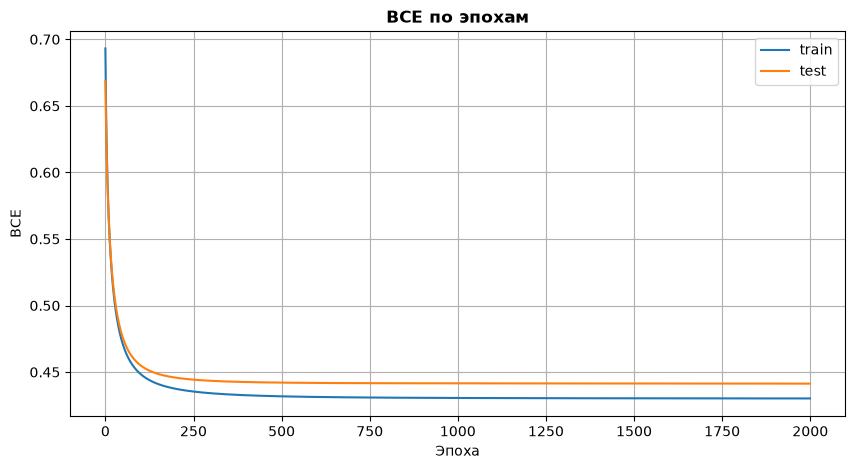

In [192]:
plt.plot(model_b.loss_history, label='train')
plt.plot(model_b.val_loss_history, label='test')
plt.title('BCE по эпохам')
plt.xlabel('Эпоха')
plt.ylabel('BCE')
plt.legend()
plt.show()

## 8. Часть B. Метрики

In [193]:
def evaluate_b(y_true, y_pred, y_proba):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'LogLoss': log_loss(y_true, y_proba),
    }

results_b = pd.DataFrame({
    'LogisticRegression, train': evaluate_b(y_train_b, model_b.predict(X_train_b_s), model_b.predict_proba(X_train_b_s)),
    'LogisticRegression, test': evaluate_b(y_test_b, model_b.predict(X_test_b_s), model_b.predict_proba(X_test_b_s)),
}).T
results_b.round(4)

,Accuracy,Precision,Recall,F1,LogLoss
"LogisticRegression, train",0.7920,0.7858,0.8127,0.7990,0.4302
"LogisticRegression, test",0.7848,0.7723,0.7970,0.7845,0.4413


## 9. Часть B. Confusion matrix

In [197]:
tn, fp, fn, tp = confusion_matrix(y_test_b, model_b.predict(X_test_b_s)).ravel()
print(f'TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}')


TP: 1021, FP: 301, FN: 260, TN: 1025


## 10. Часть B. Majority baseline
Majority Baseline будет состоять из предсказывания самого частого класса из train выборки.

In [202]:
majority_class = float(y_train_b.mean() >= 0.5)
p_majority = y_train_b.mean().item()
print(f'Самый частый класс train: {majority_class}, доля класса 1: {p_majority:.4f}')

y_pred_maj_train = torch.full_like(y_train_b, majority_class)
y_pred_maj_test = torch.full_like(y_test_b, majority_class)
y_proba_maj_train = torch.full_like(y_train_b, p_majority)
y_proba_maj_test = torch.full_like(y_test_b, p_majority)

results_b = pd.DataFrame({
    'LogisticRegression, train': evaluate_b(y_train_b, model_b.predict(X_train_b_s), model_b.predict_proba(X_train_b_s)),
    'Majority, train': evaluate_b(y_train_b, y_pred_maj_train, y_proba_maj_train),
    'LogisticRegression, test': evaluate_b(y_test_b, model_b.predict(X_test_b_s), model_b.predict_proba(X_test_b_s)),
    'Majority, test': evaluate_b(y_test_b, y_pred_maj_test, y_proba_maj_test),
}).T
results_b.round(4)

Самый частый класс train: 1.0, доля класса 1: 0.5089


,Accuracy,Precision,Recall,F1,LogLoss
"LogisticRegression, train",0.7920,0.7858,0.8127,0.7990,0.4302
"Majority, train",0.5089,0.5089,1.0000,0.6745,0.6930
"LogisticRegression, test",0.7848,0.7723,0.7970,0.7845,0.4413
"Majority, test",0.4914,0.4914,1.0000,0.6590,0.6936


# 11. Вывод по части B

Я обучил логистическую регрессию на `26` признаках после заполнения пропусков, one-hot кодирования и стандартизации. LogLoss на train снизился с `0.6931` до `0.4302`, на test идёт рядом и не растёт, переобучения нет.

F1 равен `0.78`, что очень выглядит солидно без детальной обработки признаков, добавления, удаленя или логарифмирования.

То, что `baseline` дал F1 = `0.65`, то это только потому, что baseline предсказывает всегда истинно положительный класс, recall в таком случае =`1.0`, что очень сильно скашивает метрику `F1`. При этом для `baseline` доля верных классификаций всего `0.49`.

На test модель верно классифицирует `78.5%` пассажиров против `49.1%` у majority baseline, LogLoss снизился с `0.6936` до `0.4413`.

Ошибки распределены почти поровну: `301` ложноположительный ответ и `260` ложноотрицательных, порог `0.5` не смещает модель к одному классу.


### Дополнение к части B. Что можно улучшить

Посмотрим на распределения трат в разных категориях и на долю целевой переменной `Transported` у тративших и не тративших.

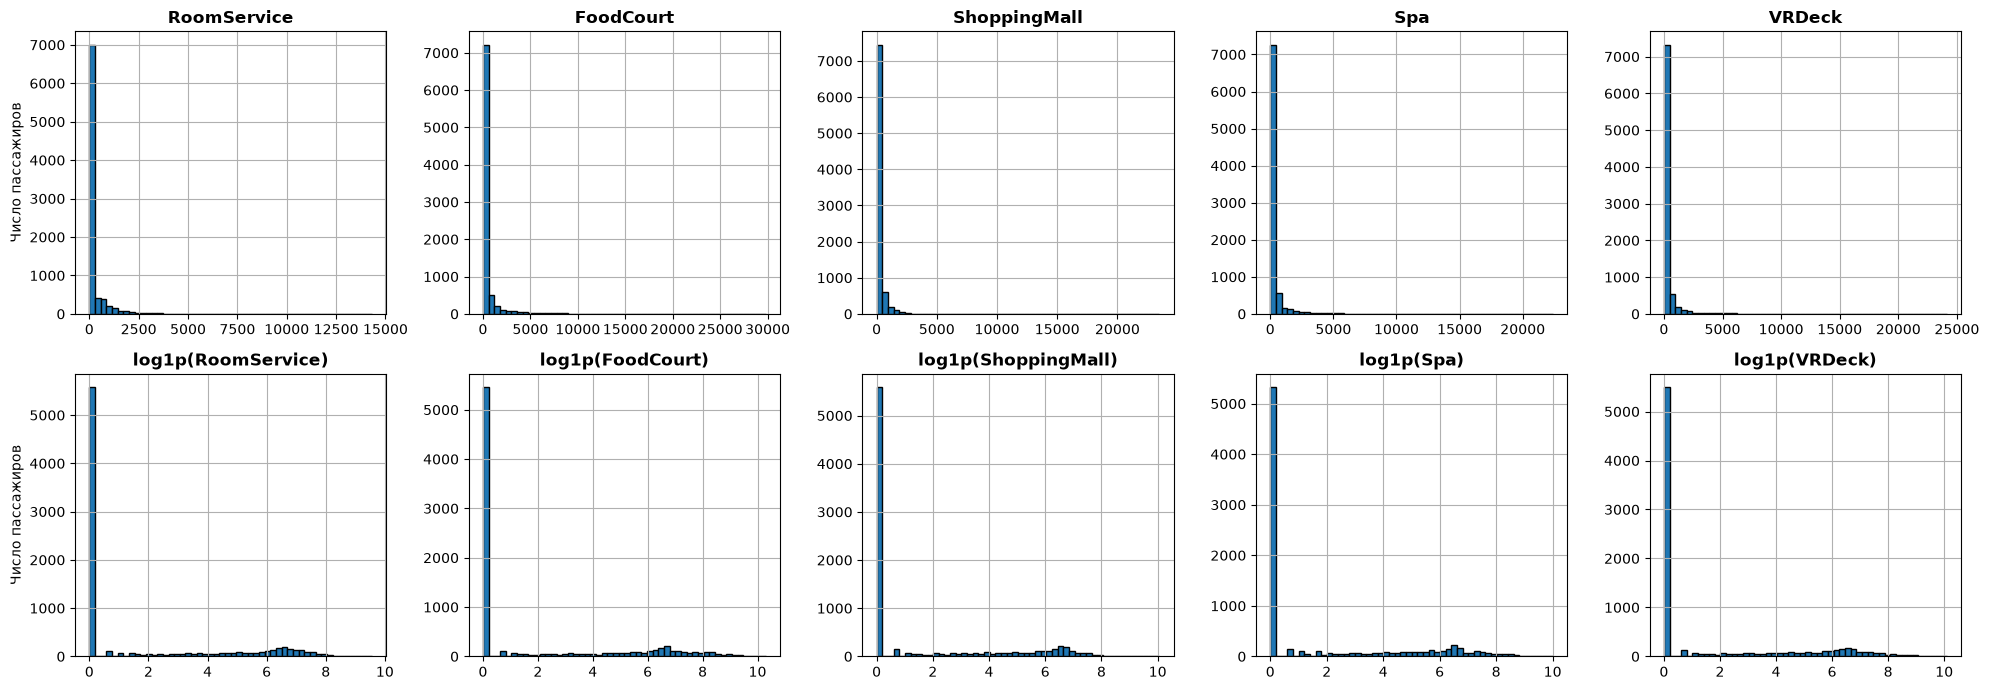

In [203]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, c in enumerate(SPEND_COLS):
    axes[0, i].hist(df_b[c].dropna(), bins=50, edgecolor='black')
    axes[0, i].set_title(c)
    axes[1, i].hist(np.log1p(df_b[c].dropna()), bins=50, edgecolor='black')
    axes[1, i].set_title(f'log1p({c})')
axes[0, 0].set_ylabel('Число пассажиров')
axes[1, 0].set_ylabel('Число пассажиров')
plt.tight_layout()
plt.show()

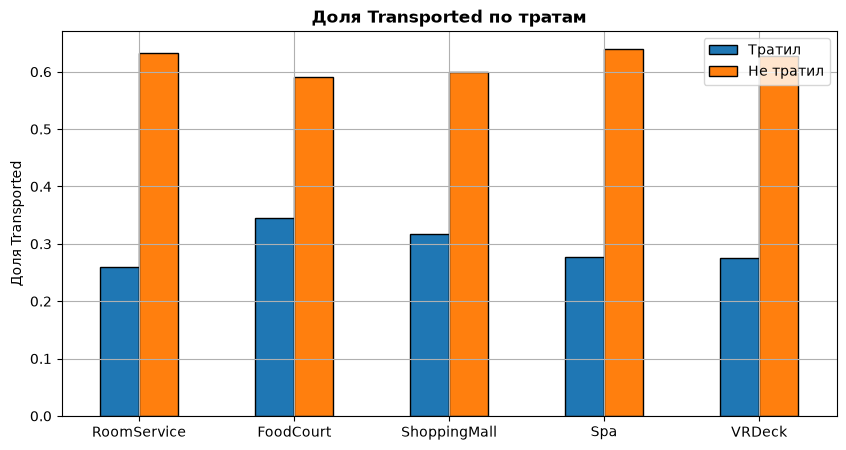

,Тратил,Не тратил
RoomService,0.260,0.633
FoodCourt,0.345,0.591
ShoppingMall,0.317,0.599
Spa,0.277,0.639
VRDeck,0.275,0.628


In [204]:
share = pd.DataFrame({
    'Тратил': [df_b.loc[df_b[c] > 0, 'Transported'].mean() for c in SPEND_COLS],
    'Не тратил': [df_b.loc[df_b[c] == 0, 'Transported'].mean() for c in SPEND_COLS],
}, index=SPEND_COLS)
share.plot.bar(rot=0, edgecolor='black')
plt.title('Доля Transported по тратам')
plt.ylabel('Доля Transported')
plt.show()
share.round(3)